# Lesson 8 - Functions of multiple variables
So far we have focused on functions of a single variable, where we have examined properties such as limits, continuity, and differentiation. Today we take the next step and introduce functions of multiple variables. These functions are fundamental in many applications within engineering, economics, and data analysis.

A function of multiple variables is a function that takes several inputs and produces a single output. In this course we will mainly focus on functions of two variables, i.e., functions $f: \mathbb{R}^2 \to \mathbb{R}$.


> ### Today's lesson
> * **Topic**: Functions of multiple variables - partial derivatives and optimization in multiple dimensions.
> * **Mathematics**: partial derivatives, the Hessian matrix and the determinant test, critical points in 2D.
> * **Python today**: 3D plots (`plot_surface`, `np.meshgrid`), `sympy.solve` with multiple symbols, `sympy.Matrix`.
> * **Remember**: Run the cells from top to bottom. If something behaves strangely: *Runtime → Restart session and run all*.


### Example: $f(x,y)=x^2+y^2$

In this example we look at the function $f(x,y)=x^2+y^2$. This function represents a paraboloid. We start by visualizing this function.

In [1]:
# The usual packages
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, diff, solve

# Import a tool for making 3D visualizations in matplotlib
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# Define the function
def f(x, y):
    return x**2 + y**2

In [3]:
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)

In [4]:
X, Y = np.meshgrid(x, y)
Z = f(X, Y)

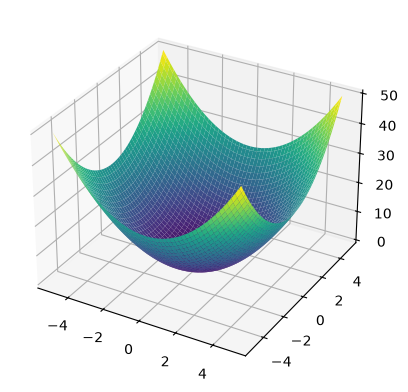

In [5]:
# Plot the function
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')

plt.show()

### Partial Derivatives

When we differentiate a function of multiple variables, we need to account for each variable separately. This gives us the so-called "partial derivatives".

Partial derivatives describe how the function changes when we change one of the independent variables while holding the other constant.

In [6]:
# Define x and y as symbols
x, y = symbols('x y')

# Define the function, f
f = x**2 + y**2

In [7]:
f_x = diff(f, x)  # differentiate with respect to x
f_y = diff(f, y)  # differentiate with respect to y

In [8]:
print('First-order partial derivatives:')
print('df/dx:', f_x)
print('df/dy:', f_y)

First-order partial derivatives:
df/dx: 2*x
df/dy: 2*y


### Critical Points

Critical points are the points where all the first-order partial derivatives equal zero or do not exist. These points are interesting because they often represent local minima, local maxima, or saddle points.

In [9]:
# Find the critical points by setting the partial derivatives equal to 0
critical_points = solve([f_x, f_y], (x, y))

print('\nCritical points:', critical_points)


Critical points: {x: 0, y: 0}


In this example, $f(x, y) = x^2 + y^2$ is a function of two variables. We visualize this function using matplotlib, which gives us a three-dimensional surface plot.

We then differentiate the function f with respect to both x and y using sympy's diff function. This gives us the first-order partial derivatives of the function.

Finally, to find the critical points of the function (i.e., places where the gradient is 0), we solve for x and y when the partial derivatives equal 0. In this case, the critical point is at (0, 0), which is the minimum point of the function.

---
## A more complex function

In this example we look at a more complex function $ f(x, y) = -2x^2 - 3y^2 + xy + 4y + 50 $. The function is again visualized using a 3D surface plot.

In [10]:
# Define the function
def f(x, y):
    return -2*x**2 - 3*y**2 + x*y + 4*y + 50

In [11]:
# Define the x and y variables
x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)

In [12]:
# Define X and Y as a meshgrid.
X, Y = np.meshgrid(x, y)

In [13]:
# Define Z as a function of X and Y
Z = f(X, Y)

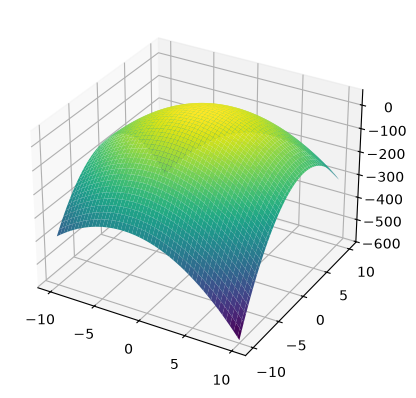

In [14]:
# Plot the function
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')

plt.show()

### First-order partial derivatives
To analyze this function further, we find the first-order partial derivatives with respect to $ x $ and $ y $.

These derivatives represent the rate of increase of the function $ f $ in the directions $ x $ and $ y $.


In [15]:
# Let's differentiate the function
x, y = symbols('x y')
f = -2*x**2 - 3*y**2 + x*y + 4*y + 50

In [16]:
f_x = diff(f, x)  # differentiate with respect to x
f_y = diff(f, y)  # differentiate with respect to y

In [17]:
print('First-order partial derivatives:')
print('df/dx:', f_x)
print('df/dy:', f_y)

First-order partial derivatives:
df/dx: -4*x + y
df/dy: x - 6*y + 4


### Critical points
We find the critical points of the function by solving the equations where the first-order partial derivatives equal 0:

\begin{equation}
\text{{Critical points: solution to }} \frac{\partial f}{\partial x} = 0 \text{{ and }} \frac{\partial f}{\partial y} = 0
\end{equation}

In [18]:
# Find the critical points by setting the partial derivatives equal to 0
critical_points = solve([f_x, f_y], (x, y))

In [19]:
print('\nCritical points:', critical_points)


Critical points: {x: 4/23, y: 16/23}


### Second-order partial derivatives
To determine the nature (maximum, minimum, or saddle point) of the critical points, we find the second-order partial derivatives:

\begin{equation}
\frac{\partial^2 f}{\partial x^2} = \text{{d}}^2f/\text{{dx}}^2, \quad \frac{\partial^2 f}{\partial y^2} = \text{{d}}^2f/\text{{dy}}^2, \quad \frac{\partial^2 f}{\partial x \partial y} = \text{{d}}^2f/\text{{dxdy}}
\end{equation}

#### On the second-order partial derivatives $ f_{xy} $ and $ f_{yx} $

In mathematics, it is generally the case that if a function is sufficiently "smooth" (continuous and differentiable), the mixed second-order partial derivatives will be equal. This is known as **Schwarz's theorem**, and it can be formulated as:

\begin{equation}
\frac{\partial^2 f}{\partial x \partial y} = \frac{\partial^2 f}{\partial y \partial x}
\end{equation}

If this is the case, and $ f_{xy} $ has already been computed, there is no need to compute $ f_{yx} $, since they will be equal. Therefore $ f_{yx} $ can in many cases be considered redundant in the calculations, especially if we are confident that the function satisfies the conditions of Schwarz's theorem.

In practice, both values are often computed as a form of double-check, to make sure the function actually satisfies these conditions. But if $ f_{yx} $ is not used in further calculations, it can be considered redundant.


In [20]:
# second-order partial derivatives
f_xx = diff(f_x, x)
f_yy = diff(f_y, y)
f_xy = diff(f_x, y)
f_yx = diff(f_y, x)

In [21]:
print('Second-order partial derivatives:')
print('d^2f/dx^2:', f_xx)
print('d^2f/dy^2:', f_yy)
print('d^2f/dxdy:', f_xy)
print('d^2f/dydx:', f_yx)

Second-order partial derivatives:
d^2f/dx^2: -4
d^2f/dy^2: -6
d^2f/dxdy: 1
d^2f/dydx: 1


### Hessian Determinant
We can now compute the Hessian determinant, $ D $, which is given by:

\begin{equation}
D = \frac{\partial^2 f}{\partial x^2} \frac{\partial^2 f}{\partial y^2} - \left( \frac{\partial^2 f}{\partial x \partial y} \right)^2
\end{equation}

In [22]:
# Hessian determinant, D = f_xx*f_yy - f_xy^2
D = f_xx*f_yy - f_xy**2
print(f"The determinant of the Hessian matrix is {D}")

The determinant of the Hessian matrix is 23


### Testing critical points
Finally, we can use the Hessian determinant and the second-order partial derivatives to determine the nature of the critical points:

* If $ D > 0 $ and $ \frac{\partial^2 f}{\partial x^2} > 0 $ (or $ \frac{\partial^2 f}{\partial y^2} > 0 $), we have a local minimum.
* If $ D > 0 $ and $ \frac{\partial^2 f}{\partial x^2} < 0 $ (or $ \frac{\partial^2 f}{\partial y^2} < 0 $), we have a local maximum.
* If $ D < 0 $, we have a saddle point.
* If $ D = 0 $, the test is inconclusive.

In [23]:
# Test the critical point
D_val = D.subs(critical_points)
f_xx_val = f_xx.subs(critical_points)

if D_val > 0 and f_xx_val > 0:
    print(f"The point {critical_points} is a local minimum.")
elif D_val > 0 and f_xx_val < 0:
    print(f"The point {critical_points} is a local maximum.")
elif D_val < 0:
    print(f"The point {critical_points} is a saddle point.")
else:
    print("The test is inconclusive for the point", critical_points)

The point {x: 4/23, y: 16/23} is a local maximum.


### Explanation of the `.subs()` Function in Sympy and Its Role in the Calculation

In our code we use the `.subs()` method from the Sympy library. The purpose of this method is to replace symbolic variables with concrete numbers. In our case we use it to substitute the critical points (x, y) into the second-order partial derivatives (`f_xx`) and the Hessian determinant (`D`).

You may have noticed that the values of `f_xx` and `D` do not change after the substitution. This is because in this example we have worked with a function whose partial derivatives and determinant do not depend on the critical points. In general cases, however, the values will change, and it is therefore important to perform this substitution to precisely determine whether a critical point is a minimum, maximum, or saddle point.

In some cases, the second-order partial derivatives and the Hessian determinant ($D$) can be functions of the variables ($x$, $y$). In such cases it is necessary to use .subs() to evaluate their values at the critical points.

Let's look at an example:

We consider a function $f(x,y)=x^3-3xy+y^3$.

In [24]:
# Define variables and function
x, y = symbols('x y')
f = x**3 - 3*x*y + y**3

In [25]:
# First-order partial derivatives
f_x = diff(f, x)
f_y = diff(f, y)

In [26]:
# Find the critical points
critical_points = solve([f_x, f_y], (x, y))

In [27]:
critical_points

[(0, 0),
 (1, 1),
 ((-1/2 - sqrt(3)*I/2)**2, -1/2 - sqrt(3)*I/2),
 ((-1/2 + sqrt(3)*I/2)**2, -1/2 + sqrt(3)*I/2)]

#### Real vs. complex solutions

Note the output above: `solve` found four solutions, but two of them contain $i = \sqrt{-1}$ - they are **complex numbers**. Our function lives in the real $(x, y)$-plane, so only the **real** solutions are actual critical points. We filter those out with a list comprehension before we classify:


In [28]:
# Keep only the real solutions - only they are critical points of the function
real_points = [p for p in critical_points if all(coord.evalf().is_real for coord in p)]
real_points

[(0, 0), (1, 1)]

In [29]:
# Second-order partial derivatives
f_xx = diff(f_x, x)
f_yy = diff(f_y, y)
f_xy = diff(f_x, y)

In [30]:
# Hessian determinant, D
D = f_xx*f_yy - f_xy**2

In [31]:
f_xx

6*x

In [32]:
# Evaluate D and f_xx at the real critical points
for point in real_points:
    # Pack the values into a dictionary
    subs_dict = {x: point[0], y: point[1]}

    D_val = D.subs(subs_dict)
    f_xx_val = f_xx.subs(subs_dict)

    if D_val > 0 and f_xx_val > 0:
        print(f"The point {point} is a local minimum.")
    elif D_val > 0 and f_xx_val < 0:
        print(f"The point {point} is a local maximum.")
    elif D_val < 0:
        print(f"The point {point} is a saddle point.")
    else:
        print(f"The test is inconclusive for the point {point}")

The point (0, 0) is a saddle point.
The point (1, 1) is a local minimum.


In [33]:
# Define the function
def f(x, y):
    return x**3 - 3*x*y + y**3

In [34]:
# Define the x and y variables
x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)

In [35]:
# Define X and Y as a meshgrid.
X, Y = np.meshgrid(x, y)

In [36]:
# Define Z as a function of X and Y
Z = f(X, Y)

In [37]:
# The two real critical points
x1, y1, z1 = 0, 0, f(0, 0)
x2, y2, z2 = 1, 1, f(1, 1)

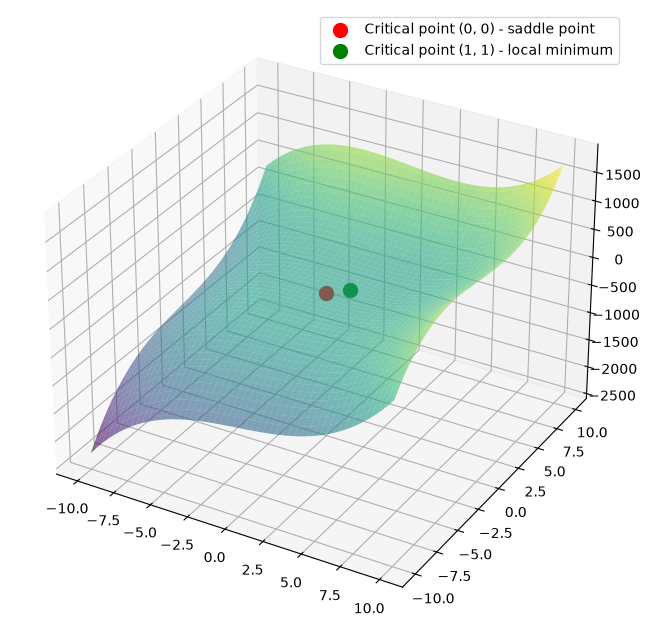

In [38]:
# Plot the function
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.6)
ax.scatter(x1, y1, z1, c='r', marker='o', s=100, label='Critical point (0, 0) - saddle point')
ax.scatter(x2, y2, z2, c='g', marker='o', s=100, label='Critical point (1, 1) - local minimum')

ax.legend()

plt.show()

## Example: solving a function with many variables (not part of the curriculum)
This part is not part of the curriculum, but after preparing the lecture, I became curious how solving systems with many unknown variables would look. The more unknowns there are, the more complex the calculations become, and so it also gets harder to use the libraries we have used so far. In this example we use Sympy, which is usable up to around 4 unknowns (or more, if you are patient). If you are interested in working further with functions of many unknowns, the Python library SciPy is built for complex mathematical calculations and solving large systems.

It also becomes harder to get an intuitive feel for whether you are taking the correct steps, since it is not possible to visualize systems with many variables.

In [39]:
from sympy import symbols, diff, solve, Matrix

# Define variables and function
x1, x2, x3, x4 = symbols('x1 x2 x3 x4')
f = x1**2 + x2**2 - x3**2 - x4**2

In [40]:
# Compute the partial derivatives
partial_x1 = diff(f, x1)
partial_x2 = diff(f, x2)
partial_x3 = diff(f, x3)
partial_x4 = diff(f, x4)

In [41]:
# Find the critical points by solving the system of equations
critical_points = solve([partial_x1, partial_x2, partial_x3, partial_x4], (x1, x2, x3, x4))

In [42]:
# Compute the Hessian matrix
hessian = Matrix([[diff(partial_x1, x1), diff(partial_x1, x2), diff(partial_x1, x3), diff(partial_x1, x4)],
                  [diff(partial_x2, x1), diff(partial_x2, x2), diff(partial_x2, x3), diff(partial_x2, x4)],
                  [diff(partial_x3, x1), diff(partial_x3, x2), diff(partial_x3, x3), diff(partial_x3, x4)],
                  [diff(partial_x4, x1), diff(partial_x4, x2), diff(partial_x4, x3), diff(partial_x4, x4)]])

In [43]:
hessian

Matrix([
[2, 0,  0,  0],
[0, 2,  0,  0],
[0, 0, -2,  0],
[0, 0,  0, -2]])

In [44]:
# Print critical points
print("Critical points: ", critical_points)

Critical points:  {x1: 0, x2: 0, x3: 0, x4: 0}


In [45]:
critical_points

{x1: 0, x2: 0, x3: 0, x4: 0}

In [46]:
# Compute the Hessian matrix at the critical point
hessian_at_point = hessian.subs(critical_points)

In [47]:
hessian_at_point

Matrix([
[2, 0,  0,  0],
[0, 2,  0,  0],
[0, 0, -2,  0],
[0, 0,  0, -2]])

In [48]:
# Compute eigenvalues
eigen_values = hessian_at_point.eigenvals()

In [49]:
# Print eigenvalues
print(f"Eigenvalues at the point {critical_points}: {eigen_values}")

Eigenvalues at the point {x1: 0, x2: 0, x3: 0, x4: 0}: {2: 2, -2: 2}


In [50]:
# Classify the critical point
if all(val > 0 for val in eigen_values):
    print(f"The point {critical_points} is a local minimum.")
elif all(val < 0 for val in eigen_values):
    print(f"The point {critical_points} is a local maximum.")
else:
    print(f"The point {critical_points} is a saddle point.")

The point {x1: 0, x2: 0, x3: 0, x4: 0} is a saddle point.


## Explanation: Why do we use eigenvalues to classify critical points?

When we work with functions of multiple variables, e.g. $ f(x_1, x_2, \ldots, x_n) $, one of our tasks is to identify and classify critical points. Critical points are places where all first-order partial derivatives equal zero. These points are of interest because they often represent local minimum or maximum values, or other interesting properties of the function.

### What is the Hessian matrix?

To classify these critical points, we often use the Hessian matrix. This $ n \times n $ matrix is a collection of the function's second-order partial derivatives. The Hessian matrix gives us important information about how the function "curves" around a given point.

### Why are eigenvalues important?

The eigenvalues of the Hessian matrix give us specific indications about this "curving":

- **All positive eigenvalues**: If all eigenvalues are positive, we have a "bowl"-shaped region around the critical point. This indicates that the critical point is a **local minimum**.

- **All negative eigenvalues**: Conversely, if all eigenvalues are negative, we have a "dome"-shaped region. This indicates that the critical point is a **local maximum**.

- **Mixed eigenvalues**: If we have both positive and negative eigenvalues, the function has a "saddle" shape near the critical point. This means the critical point is a **saddle point**, which is neither a minimum nor a maximum.

### Summary

The eigenvalues of the Hessian matrix thus give us a method to geometrically understand and classify critical points in functions of multiple variables. They help us determine whether a critical point is a local minimum, a local maximum, or a saddle point.
